In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/Loan_default.csv")

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())
display(df.describe())

FileNotFoundError: [Errno 2] No such file or directory: 'data/Loan_default.csv'

In [3]:
from pathlib import Path

project = Path(r"D:\loan-default-risk")

print("Project folder exists:", project.exists())

for file in project.rglob("Loan_default.csv"):
    print("Dataset found:", file)

Project folder exists: True
Dataset found: D:\loan-default-risk\data\Loan_default.csv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"D:\loan-default-risk\data\Loan_default.csv")

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())
display(df.describe())

Dataset shape: (255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str    
 17  Default         25534

None

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [7]:
print(df["Default"].value_counts())
print(df["Default"].value_counts(normalize=True) * 100)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Default
0    225694
1     29653
Name: count, dtype: int64
Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64
Missing values: 0
Duplicate rows: 0


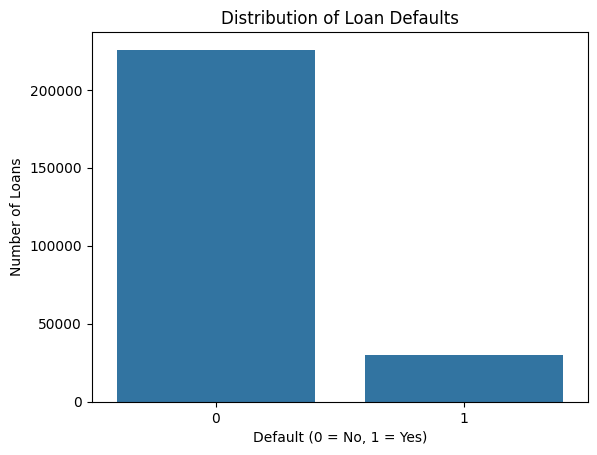

In [8]:
sns.countplot(data=df, x="Default")

plt.title("Distribution of Loan Defaults")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Number of Loans")
plt.show()

In [9]:
df["IncomeBand"] = pd.cut(
    df["Income"],
    bins=[0, 25000, 50000, 75000, 100000, 125000, 150000],
    labels=[
        "0-25K",
        "25K-50K",
        "50K-75K",
        "75K-100K",
        "100K-125K",
        "125K-150K"
    ],
    include_lowest=True
)

Calculate the default rate for each group:

In [10]:
income_analysis = (
    df.groupby("IncomeBand", observed=False)
      .agg(
          TotalLoans=("Default", "size"),
          Defaults=("Default", "sum"),
          DefaultRate=("Default", "mean")
      )
      .reset_index()
)

income_analysis["DefaultRate"] *= 100

display(income_analysis)

,IncomeBand,TotalLoans,Defaults,DefaultRate
0,0-25K,19048,4584,24.065519
1,25K-50K,47051,6760,14.367389
2,50K-75K,47366,5047,10.655322
3,75K-100K,47317,4653,9.833675
4,100K-125K,47406,4391,9.262541
5,125K-150K,47159,4218,8.944210


Visualize the results:

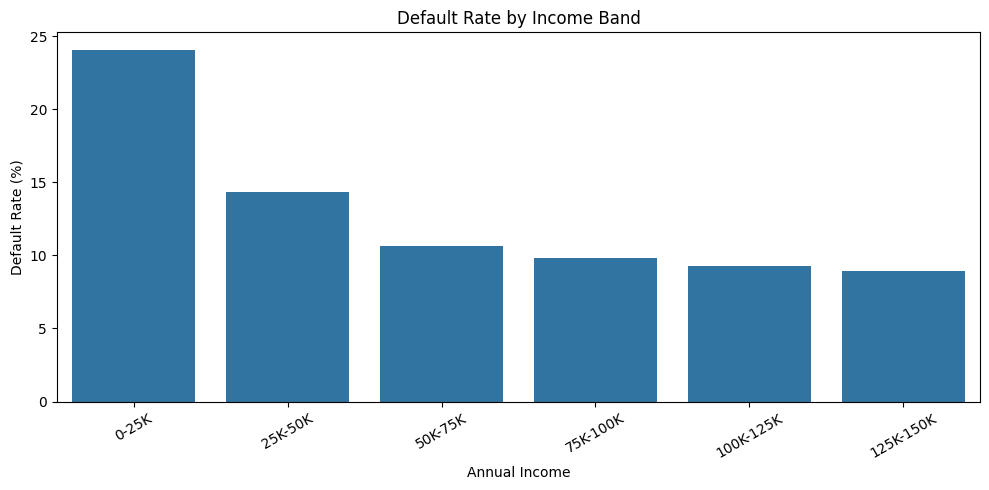

In [11]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=income_analysis,
    x="IncomeBand",
    y="DefaultRate"
)

plt.title("Default Rate by Income Band")
plt.xlabel("Annual Income")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Analyze default rate by age

In [12]:
df["AgeBand"] = pd.cut(
    df["Age"],
    bins=[18, 25, 35, 45, 55, 65, 70],
    labels=[
        "18-24",
        "25-34",
        "35-44",
        "45-54",
        "55-64",
        "65-69"
    ],
    right=False
)

age_analysis = (
    df.groupby("AgeBand", observed=False)
      .agg(
          TotalLoans=("Default", "size"),
          Defaults=("Default", "sum"),
          DefaultRate=("Default", "mean")
      )
      .reset_index()
)

age_analysis["DefaultRate"] *= 100

display(age_analysis)

,AgeBand,TotalLoans,Defaults,DefaultRate
0,18-24,34176,7188,21.032303
1,25-34,49287,8160,16.556090
2,35-44,49196,5895,11.982682
3,45-54,49069,4295,8.752980
4,55-64,49100,2927,5.961303
5,65-69,24519,1188,4.845222


Create the chart:

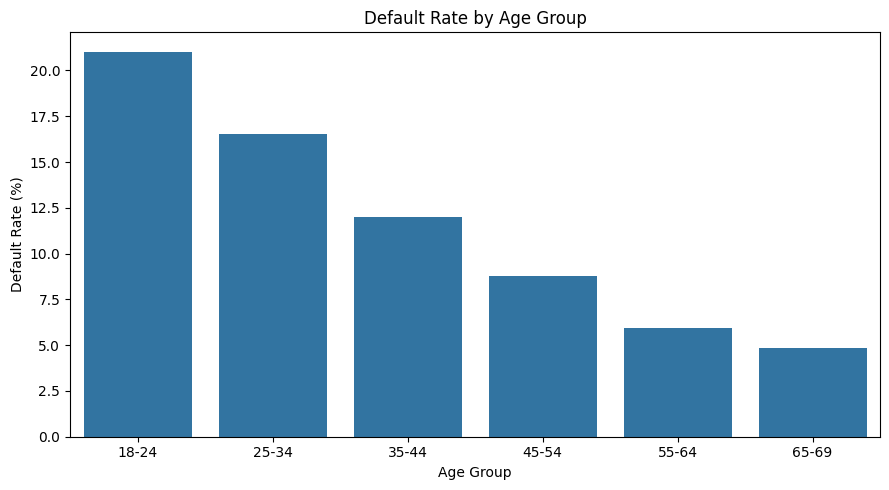

In [13]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_analysis,
    x="AgeBand",
    y="DefaultRate"
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

Analyze default rate by loan purpose

In [14]:
purpose_analysis = (
    df.groupby("LoanPurpose")
      .agg(
          TotalLoans=("Default", "size"),
          Defaults=("Default", "sum"),
          TotalLoanAmount=("LoanAmount", "sum"),
          DefaultRate=("Default", "mean")
      )
      .reset_index()
)

purpose_analysis["DefaultRate"] *= 100

display(
    purpose_analysis.sort_values(
        "DefaultRate", ascending=False
    )
)

,LoanPurpose,TotalLoans,Defaults,TotalLoanAmount,DefaultRate
1,Business,51298,6323,6522120439,12.326017
0,Auto,50844,6041,6500807511,11.881441
2,Education,51005,6038,6510575194,11.838055
4,Other,50914,6002,6498135901,11.788506
3,Home,51286,5249,6545241527,10.234762


Visualize it:

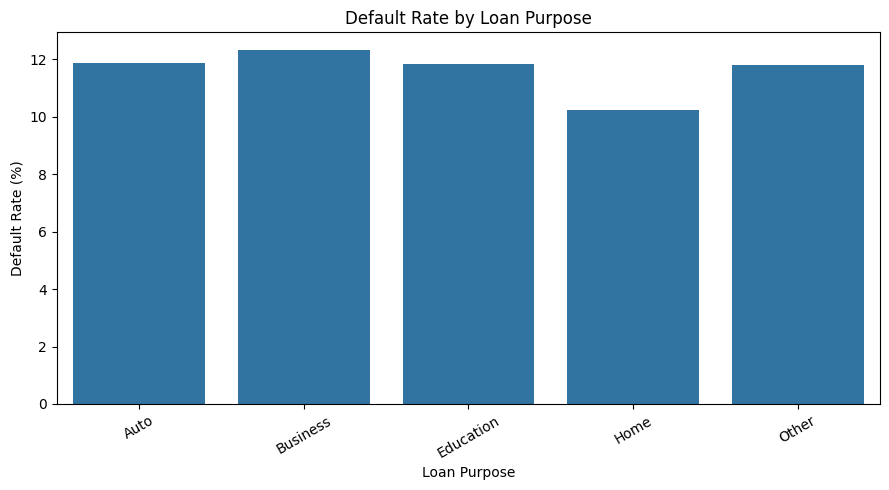

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=purpose_analysis,
    x="LoanPurpose",
    y="DefaultRate"
)

plt.title("Default Rate by Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xlabel("Loan Purpose")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Analyze credit score and debt-to-income ratio

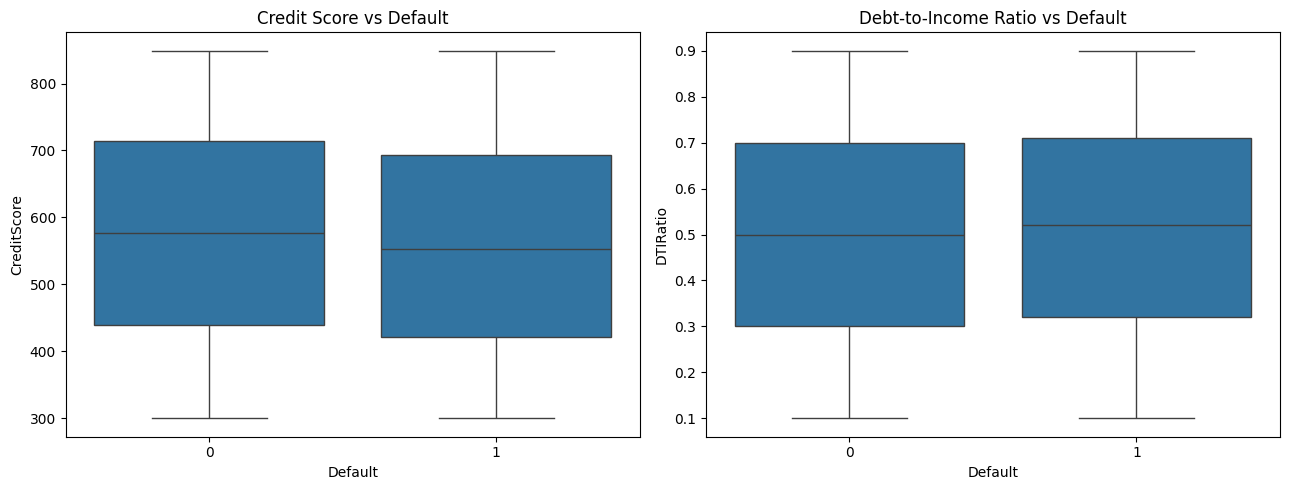

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df,
    x="Default",
    y="CreditScore",
    ax=axes[0]
)
axes[0].set_title("Credit Score vs Default")

sns.boxplot(
    data=df,
    x="Default",
    y="DTIRatio",
    ax=axes[1]
)
axes[1].set_title("Debt-to-Income Ratio vs Default")

plt.tight_layout()
plt.show()

Find which segments contribute the most loan exposure

In [17]:
portfolio = (
    df.groupby("LoanPurpose")
      .agg(
          TotalLoans=("Default", "size"),
          Defaults=("Default", "sum"),
          TotalLoanAmount=("LoanAmount", "sum")
      )
      .reset_index()
)

portfolio["DefaultRate"] = (
    portfolio["Defaults"] / portfolio["TotalLoans"] * 100
)

portfolio["LoanAmountShare"] = (
    portfolio["TotalLoanAmount"] /
    portfolio["TotalLoanAmount"].sum() * 100
)

display(
    portfolio.sort_values(
        "TotalLoanAmount", ascending=False
    )
)

,LoanPurpose,TotalLoans,Defaults,TotalLoanAmount,DefaultRate,LoanAmountShare
3,Home,51286,5249,6545241527,10.234762,20.091677
1,Business,51298,6323,6522120439,12.326017,20.020703
2,Education,51005,6038,6510575194,11.838055,19.985263
0,Auto,50844,6041,6500807511,11.881441,19.955279
4,Other,50914,6002,6498135901,11.788506,19.947078


This gives you three useful measures:
- DefaultRate: percentage of loans that defaulted in a segment.
- TotalLoanAmount: sum of the original loan amounts in that segment.
- LoanAmountShare: percentage of the dataset's original loan amount associated with that segment.

Analyze other borrower categories

In [18]:
for col in [
    "EmploymentType",
    "Education",
    "HasMortgage",
    "HasDependents",
    "HasCoSigner"
]:
    print(f"\nDefault analysis by {col}")

    result = (
        df.groupby(col, dropna=False)
          .agg(
              TotalLoans=("Default", "size"),
              Defaults=("Default", "sum"),
              DefaultRate=("Default", "mean")
          )
          .reset_index()
    )

    result["DefaultRate"] *= 100
    display(result)


Default analysis by EmploymentType


,EmploymentType,TotalLoans,Defaults,DefaultRate
0,Full-time,63656,6024,9.463366
1,Part-time,64161,7677,11.965213
2,Self-employed,63706,7302,11.462029
3,Unemployed,63824,8650,13.552895



Default analysis by Education


,Education,TotalLoans,Defaults,DefaultRate
0,Bachelor's,64366,7789,12.101109
1,High School,63903,8230,12.878895
2,Master's,63541,6908,10.871721
3,PhD,63537,6726,10.585958



Default analysis by HasMortgage


,HasMortgage,TotalLoans,Defaults,DefaultRate
0,No,127670,15761,12.345108
1,Yes,127677,13892,10.880581



Default analysis by HasDependents


,HasDependents,TotalLoans,Defaults,DefaultRate
0,No,127605,16237,12.724423
1,Yes,127742,13416,10.502419



Default analysis by HasCoSigner


,HasCoSigner,TotalLoans,Defaults,DefaultRate
0,No,127646,16423,12.866051
1,Yes,127701,13230,10.360138


Examine correlations

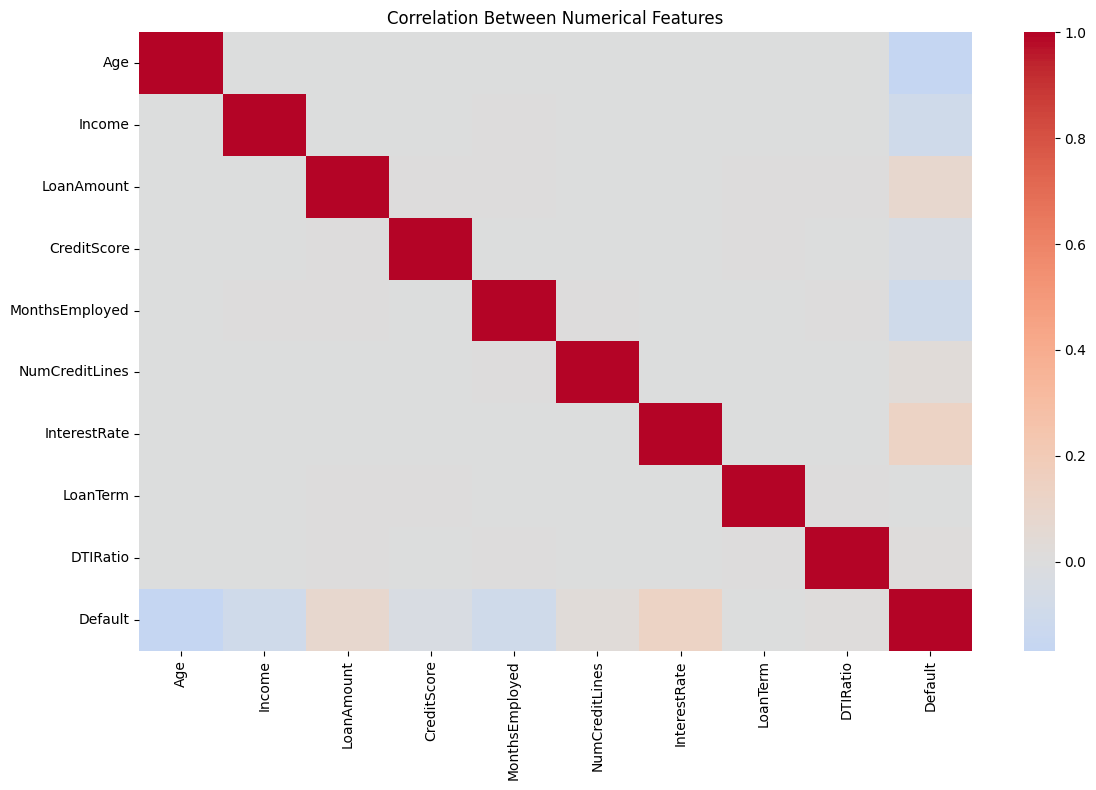

In [19]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

Prepare the data for machine learning

Separate features and target

In [20]:
from sklearn.model_selection import train_test_split

X = df.drop(
    columns=["Default", "LoanID", "IncomeBand", "AgeBand"],
    errors="ignore"
)

y = df["Default"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 204277
Testing rows: 51070


Encode categorical columns

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score
)

numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

C:\Users\manoj\AppData\Local\Temp\ipykernel_24608\1050211066.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


This approach is useful because you don't have to manually encode every category or scale every numeric column.

# Logistic Regression 

In [22]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, logistic_probabilities)
)

              precision    recall  f1-score   support

           0       0.94      0.67      0.79     45139
           1       0.22      0.70      0.33      5931

    accuracy                           0.68     51070
   macro avg       0.58      0.69      0.56     51070
weighted avg       0.86      0.68      0.73     51070

ROC-AUC: 0.753178399553392


# Random Forest

In [23]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, rf_probabilities)
)

              precision    recall  f1-score   support

           0       0.90      0.96      0.93     45139
           1       0.41      0.23      0.30      5931

    accuracy                           0.87     51070
   macro avg       0.66      0.59      0.61     51070
weighted avg       0.85      0.87      0.86     51070

ROC-AUC: 0.7512613103071657


Compare the models

In [24]:
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": roc_auc_score(y_test, logistic_probabilities),
        "Average Precision": average_precision_score(
            y_test, logistic_probabilities
        )
    },
    {
        "Model": "Random Forest",
        "ROC-AUC": roc_auc_score(y_test, rf_probabilities),
        "Average Precision": average_precision_score(
            y_test, rf_probabilities
        )
    }
])

display(
    comparison.sort_values(
        "ROC-AUC", ascending=False
    )
)

,Model,ROC-AUC,Average Precision
0,Logistic Regression,0.753178,0.310542
1,Random Forest,0.751261,0.315922


Visualize the confusion matrix

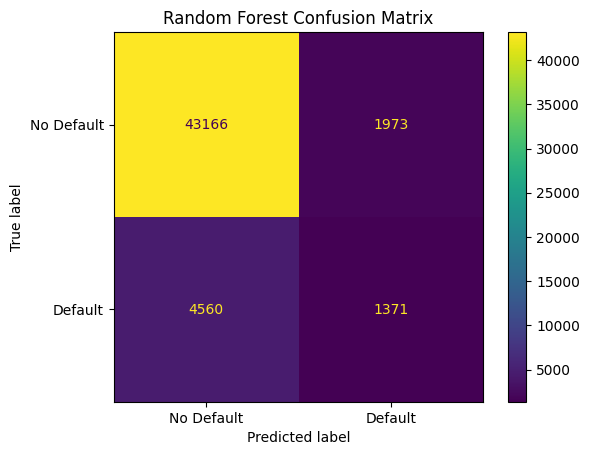

In [25]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["No Default", "Default"]
)

plt.title("Random Forest Confusion Matrix")
plt.show()

This reveals how many defaults the model identifies and how many it misses.

In [26]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    random_forest_model,
    "models/loan_default_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!
